# 梯度下降法 Gradient Descent：ML 慢慢學 EP01 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v02-gradient-descent/notebook.ipynb)

這本 notebook 重現影片裡的**每一張圖**。所有資料都是**模擬資料**（不是真實量測）。
This notebook reproduces every chart in EP01 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated**.

| 段落 | 對應影片 |
|---|---|
| 1. 模擬資料：氣溫 → 冷氣用電量 | 第 2 段 |
| 2. 損失：均方誤差 MSE | 第 3 段 |
| 3. 固定 b，只看 w：碗形曲線 | 第 4 段 |
| 4. 梯度下降一步一步走 | 第 6 段 |
| 5. 三種學習率，以及和控制系統增益的對照 | 第 7 段 |
| 6. 同時調整 w 和 b：等高線圖 | 第 8 段 |
| 7. 應用：預測明天的用電量 | 第 9 段 |
| 8. 非凸的損失地形（示意） | 第 10 段 |
| 9. 匯出資料給影片使用 | — |

參考：Goodfellow, Bengio & Courville (2016) *Deep Learning* §4.3；Google Machine Learning Crash Course（線性迴歸：梯度下降）。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Video palette (same colours as the video)
PAPER, INK, RED, BLUE, AMBER = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## 1. 模擬資料：氣溫 → 冷氣用電量
假設一台冷氣每天的用電量（度 = kWh）大致隨氣溫線性增加，再加上一點隨機雜訊。固定亂數種子，結果每次都一樣。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


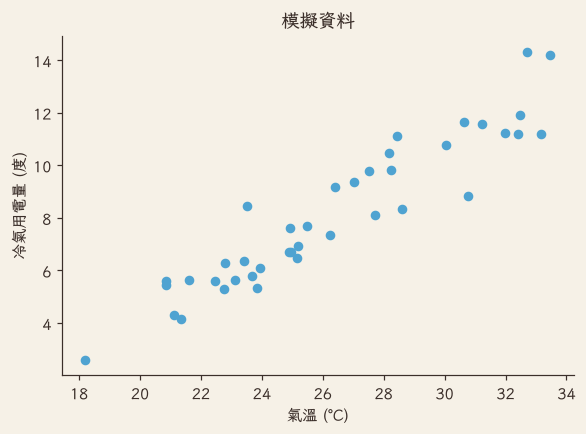

In [2]:
rng = np.random.default_rng(2026)
n = 40
temp = rng.uniform(18, 34, n)                          # x: daily temperature (°C)
kwh = 0.55 * temp - 6.5 + rng.normal(0, 0.9, n)        # y: AC electricity use (kWh), simulated

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(temp, kwh, color=BLUE, s=28)
ax.set_xlabel("氣溫 (°C)"); ax.set_ylabel("冷氣用電量 (度)"); ax.set_title("模擬資料")
plt.show()

## 2. 損失：均方誤差 MSE
直線 $\hat y = w x + b$。損失 $L(w,b)=\frac{1}{n}\sum_i (w x_i + b - y_i)^2$。

線性迴歸其實有公式解（正規方程），我們先用它算出「正確答案」$w^*, b^*$，之後拿來檢查梯度下降有沒有走對。

In [3]:
def loss(w, b):
    return np.mean((w * temp + b - kwh) ** 2)

X = np.c_[temp, np.ones(n)]
w_star, b_star = np.linalg.lstsq(X, kwh, rcond=None)[0]   # closed-form least squares
L_star = loss(w_star, b_star)
print(f"w* = {w_star:.4f} 度/°C,  b* = {b_star:.4f} 度,  最小損失 L* = {L_star:.4f}")

w* = 0.6532 度/°C,  b* = -9.0401 度,  最小損失 L* = 0.9012


## 3. 固定 b，只看 w：碗形曲線
把 $b$ 固定在 $b^*$，$L(w)$ 是一條開口向上的拋物線，碗底就在 $w^*$。
它的彎曲程度（二次微分）是 $a = \frac{d^2L}{dw^2} = \frac{2}{n}\sum x_i^2$，等一下會用到。

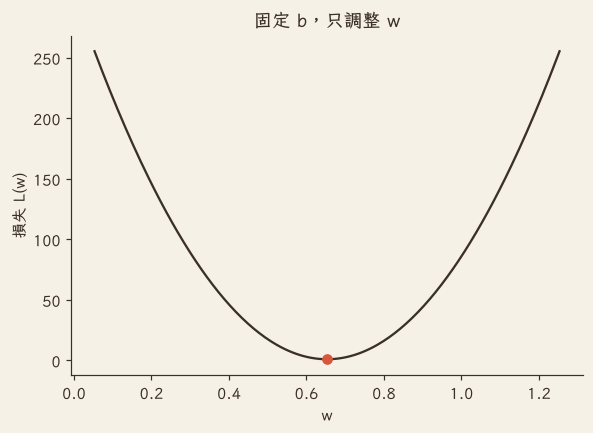

a = 1413.6


In [4]:
def loss_w(w):                     # L(w) with b fixed at b*
    return loss(w, b_star)

def grad_w(w):                     # dL/dw with b fixed at b*
    return np.mean(2 * (w * temp + b_star - kwh) * temp)

a = 2 * np.mean(temp ** 2)         # curvature of L(w)
W_RANGE = (w_star - 0.6, w_star + 0.6)
ws = np.linspace(*W_RANGE, 241)
bowl = np.array([loss_w(w) for w in ws])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ws, bowl, color=INK)
ax.scatter([w_star], [L_star], color=RED, zorder=3)
ax.set_xlabel("w"); ax.set_ylabel("損失 L(w)"); ax.set_title("固定 b，只調整 w")
plt.show()
print(f"a = {a:.1f}")

## 4. 梯度下降一步一步走
更新規則：$w \leftarrow w - \eta \, \frac{dL}{dw}$（$\eta$ 是學習率）。從碗的右邊出發：斜率是正的，所以 $w$ 會變小。

In [5]:
def run_gd_1d(w0, eta, steps):
    path = [w0]
    for _ in range(steps):
        path.append(path[-1] - eta * grad_w(path[-1]))
    return np.array(path)

w0 = w_star + 0.4
eta_good = 0.7 / a
path_good = run_gd_1d(w0, eta_good, 12)
for k, w in enumerate(path_good[:6]):
    print(f"第 {k} 步: w = {w:.4f}, 斜率 = {grad_w(w):+.3f}, 損失 = {loss_w(w):.3f}")

第 0 步: w = 1.0532, 斜率 = +565.429, 損失 = 113.987
第 1 步: w = 0.7732, 斜率 = +169.629, 損失 = 11.079
第 2 步: w = 0.6892, 斜率 = +50.889, 損失 = 1.817
第 3 步: w = 0.6640, 斜率 = +15.267, 損失 = 0.984
第 4 步: w = 0.6564, 斜率 = +4.580, 損失 = 0.909
第 5 步: w = 0.6541, 斜率 = +1.374, 損失 = 0.902


## 5. 三種學習率，以及和控制系統增益的對照
對這條拋物線，每走一步，離碗底的距離都會乘上同一個數 $(1-\eta a)$：
$$w_{k+1}-w^* = (1-\eta a)(w_k-w^*)$$
- $0<\eta a<1$：一路往碗底靠近（太小就很慢）
- $1<\eta a<2$：在兩邊來回跳，但越跳越近
- $\eta a>2$：越跳越遠，發散

這和離散控制系統裡「比例增益 $K$」的誤差 $e_{k+1}=(1-K)\,e_k$ 是同一個式子：$K$ 太小反應慢，太大會震盪、甚至不穩定。

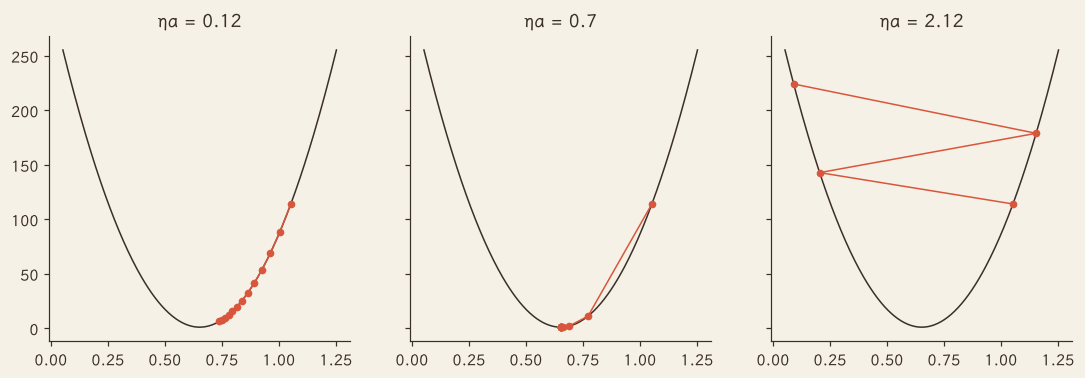

檢查通過：梯度下降的誤差序列 = (1-K)^k


In [6]:
K_LIST = [0.12, 0.7, 2.12]           # = eta * a  (small, good, too large)
runs = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, K in zip(axes, K_LIST):
    p = run_gd_1d(w0, K / a, 12)
    runs.append({"K": K, "eta": K / a, "w": p})
    ax.plot(ws, bowl, color=INK, lw=1)
    inside = (p >= W_RANGE[0]) & (p <= W_RANGE[1])
    ax.plot(p[inside], [loss_w(w) for w in p[inside]], "-o", color=RED, ms=4, lw=1)
    ax.set_title(f"ηa = {K}")
plt.show()

# Same numbers seen as a control loop: error e_k / e_0 = (1-K)^k
k = np.arange(13)
for r in runs:
    e_ratio = (r["w"] - w_star) / (w0 - w_star)
    assert np.allclose(e_ratio, (1 - r["K"]) ** k)    # GD error == P-controller error, exactly
print("檢查通過：梯度下降的誤差序列 = (1-K)^k")

## 6. 同時調整 w 和 b：等高線圖
為了讓等高線看得清楚，這裡先把氣溫**減去平均值**（中心化）：$x' = x-\bar x$。斜率 $w$ 的意思不變，$b$ 變成「平均氣溫那天的用電量」。
中心化後 $L(w,b) - L^* = \mathrm{Var}(x)\,(w-w^*)^2 + (b-b'^*)^2$，等高線是橢圓。

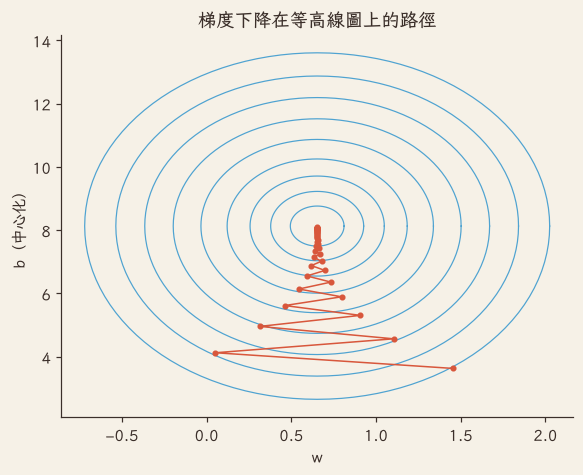

第 40 步: w = 0.6532 (w* = 0.6532), b = 8.0853 (b'* = 8.1278)


In [7]:
t_mean = temp.mean()
tc = temp - t_mean
b_c_star = kwh.mean()                  # optimal b after centering
var_t = tc.var()

def loss_c(w, b):
    return np.mean((w * tc + b - kwh) ** 2)

def grad_c(w, b):
    r = w * tc + b - kwh
    return np.mean(2 * r * tc), np.mean(2 * r)

eta2 = 0.055                          # stable only if eta < 2 / (2 * Var(x)) ≈ 0.063
p = np.array([w_star + 0.8, b_c_star - 4.5])
path2 = [p.copy()]
for _ in range(40):
    gw, gb = grad_c(*p)
    p = p - eta2 * np.array([gw, gb])
    path2.append(p.copy())
path2 = np.array(path2)

levels = [0.4, 1.2, 2.5, 4.5, 7.5, 11.5, 16.5, 22.5, 30]   # values of L - L*
th = np.linspace(0, 2 * np.pi, 121)
ellipses = [np.c_[w_star + np.sqrt(c / var_t) * np.cos(th), b_c_star + np.sqrt(c) * np.sin(th)] for c in levels]
assert abs(loss_c(*ellipses[3][7]) - L_star - levels[3]) < 1e-6   # ellipse really is a level set

fig, ax = plt.subplots(figsize=(6, 4.5))
for e in ellipses:
    ax.plot(e[:, 0], e[:, 1], color=BLUE, lw=0.8)
ax.plot(path2[:, 0], path2[:, 1], "-o", color=RED, ms=3, lw=1)
ax.set_xlabel("w"); ax.set_ylabel("b（中心化）"); ax.set_title("梯度下降在等高線圖上的路徑")
plt.show()
print(f"第 40 步: w = {path2[-1,0]:.4f} (w* = {w_star:.4f}), b = {path2[-1,1]:.4f} (b'* = {b_c_star:.4f})")

## 7. 應用：預測明天的用電量
學到 $w, b$ 後，把天氣預報的氣溫代進去。

In [8]:
T_FORECAST = 33.0
y_forecast = w_star * T_FORECAST + b_star
print(f"明天預報 {T_FORECAST:.0f}°C → 預估冷氣用電約 {y_forecast:.1f} 度（模擬資料）")

明天預報 33°C → 預估冷氣用電約 12.5 度（模擬資料）


## 8. 非凸的損失地形（示意）
神經網路的損失不是一個碗。這裡用一條自己設計的曲線**示意**：它有全域最小值、局部最小值，還有一個斜率為 0 但不是最低點的平坦處（一維的鞍點，見 Goodfellow §4.3 圖 4.2）。
$f'(x) = (x+2)(x+0.3)(x-1.2)(x-2.6)^2$，再積分得到 $f(x)$。

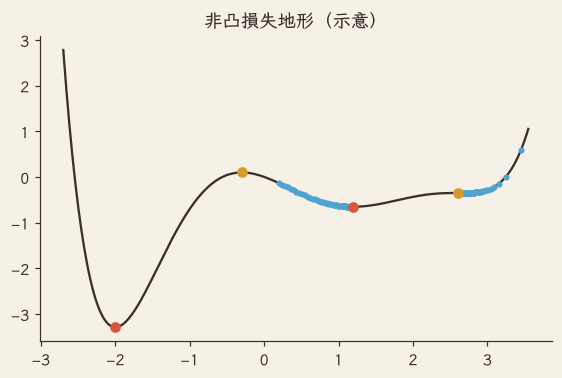

右邊出發：120 步後停在 x = 2.656，卡在平坦的鞍點 2.6 附近，越走越慢
中間出發：60 步後停在 x = 1.170，是局部最小值 1.2，不是全域最小值 -2


In [9]:
dpoly = np.poly1d([1, 2]) * np.poly1d([1, 0.3]) * np.poly1d([1, -1.2]) * np.poly1d([1, -2.6]) ** 2
fpoly = dpoly.integ()
xs = np.linspace(-2.7, 3.55, 313)
fs = fpoly(xs) * 0.12
crit = {"global_min": -2.0, "local_max": -0.3, "local_min": 1.2, "saddle": 2.6}

def descend(x0, steps, lr=0.05):
    path = [x0]
    for _ in range(steps):
        path.append(path[-1] - lr * dpoly(path[-1]) * 0.12)
    return np.array(path)

ball_saddle = descend(3.45, 120)   # starts right of the flat point
ball_local = descend(0.2, 60)      # starts between the hump and the local minimum

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(xs, fs, color=INK)
for name, cx in crit.items():
    ax.scatter([cx], [fpoly(cx) * 0.12], color=RED if "min" in name else AMBER, zorder=3)
ax.plot(ball_saddle, fpoly(ball_saddle) * 0.12, "o", color=BLUE, ms=3)
ax.plot(ball_local, fpoly(ball_local) * 0.12, "o", color=BLUE, ms=3)
ax.set_title("非凸損失地形（示意）")
plt.show()
print(f"右邊出發：120 步後停在 x = {ball_saddle[-1]:.3f}，卡在平坦的鞍點 2.6 附近，越走越慢")
print(f"中間出發：60 步後停在 x = {ball_local[-1]:.3f}，是局部最小值 1.2，不是全域最小值 -2")

## 9. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖，所以影片裡的數字和這本 notebook 完全一樣。

In [10]:
r3 = lambda v: [round(float(t), 4) for t in v]
out = {
    "meta": {"seed": 2026, "n": n, "simulated": True, "label": "模擬資料"},
    "points": [[round(float(t), 3), round(float(y), 3)] for t, y in zip(temp, kwh)],
    "fit": {"w": float(w_star), "b": float(b_star), "L": float(L_star)},
    "axes": {"temp": [16, 36], "kwh": [0, 16]},
    "bowl": {"b_fixed": float(b_star), "w": r3(ws), "L": r3(bowl), "range": list(W_RANGE), "a": float(a)},
    "gd1d": {"w0": float(w0), "good": r3(path_good),
             "runs": [{"K": r["K"], "eta": float(r["eta"]), "w": r3(r["w"]),
                       "L": r3([loss_w(w) for w in r["w"]])} for r in runs]},
    "contour": {"t_mean": float(t_mean), "w_star": float(w_star), "b_star": float(b_c_star), "eta": eta2,
                "levels": levels, "ellipses": [[r3(pt) for pt in e] for e in ellipses],
                "path": [r3(pt) for pt in path2],
                "w_range": [w_star - 1.5, w_star + 1.5], "b_range": [b_c_star - 6.5, b_c_star + 6.5]},
    "predict": {"temp": T_FORECAST, "kwh": float(y_forecast)},
    "nonconvex": {"x": r3(xs), "f": r3(fs), "crit": {k: [v, float(fpoly(v) * 0.12)] for k, v in crit.items()},
                  "balls": {k: [[round(float(x), 4), round(float(fpoly(x) * 0.12), 4)] for x in v]
                            for k, v in {"saddle": ball_saddle, "local": ball_local}.items()}},
}
Path("data").mkdir(exist_ok=True)
Path("data/v02.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print("已匯出 data/v02.json")

已匯出 data/v02.json
